In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 20        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 0  ### uncorrelated variance of disorder
LMBDA = 0
SEED = 58  ## seed for the disorder

ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [3]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY

Ep = np.empty((XCT.shape[0],K_NUM))

for i in range(XCT.shape[0]):

    H = ModCT.H_sys(PHI, 'li', XCT[i], YCT)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)/DELTA

    Ep[i,:] = Es

    print(Ep[i,:])

np.save('linear_E_vs_xct_V1.npy', Ep)

[-0.89237491 -0.88912112 -0.35817643 -0.35620216  0.35620216  0.35817643
  0.88912112  0.89237491]
[-0.89222192 -0.88896901 -0.35832107 -0.35634776  0.35634776  0.35832107
  0.88896901  0.89222192]
[-0.89197745 -0.88872585 -0.35855052 -0.35657866  0.35657866  0.35855052
  0.88872585  0.89197745]
[-0.89162219 -0.88837237 -0.35879326 -0.35682314  0.35682314  0.35879326
  0.88837237  0.89162219]
[-0.89116412 -0.8879164  -0.35884837 -0.35687972  0.35687972  0.35884837
  0.8879164   0.89116412]
[-0.89060964 -0.88736441 -0.3585698  -0.35660218  0.35660218  0.3585698
  0.88736441  0.89060964]
[-0.88997435 -0.88673214 -0.35797602 -0.35600919  0.35600919  0.35797602
  0.88673214  0.88997435]
[-0.88931337 -0.88607463 -0.35719878 -0.35523272  0.35523272  0.35719878
  0.88607463  0.88931337]
[-0.88871825 -0.8854829  -0.35642401 -0.35445867  0.35445867  0.35642401
  0.8854829   0.88871825]
[-0.88829118 -0.88505842 -0.35584092 -0.35387615  0.35387615  0.35584092
  0.88505842  0.88829118]
[-0.8881136

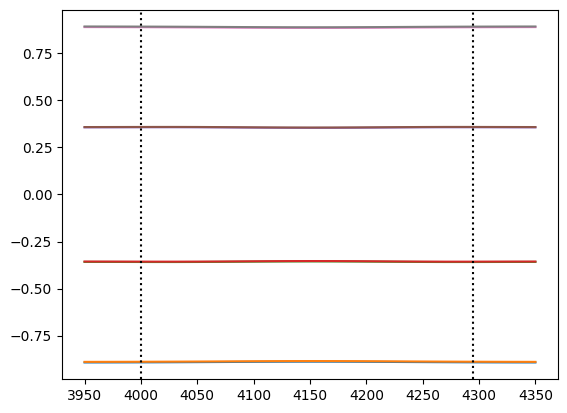

In [4]:
plt.plot(XCT, Ep[:, :])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

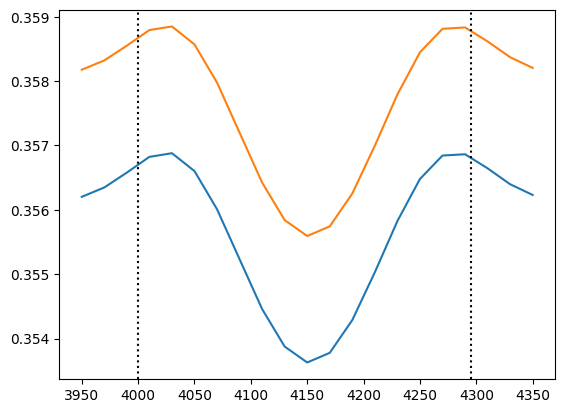

In [5]:
plt.plot(XCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

(0.0, 0.0023691305210776113)

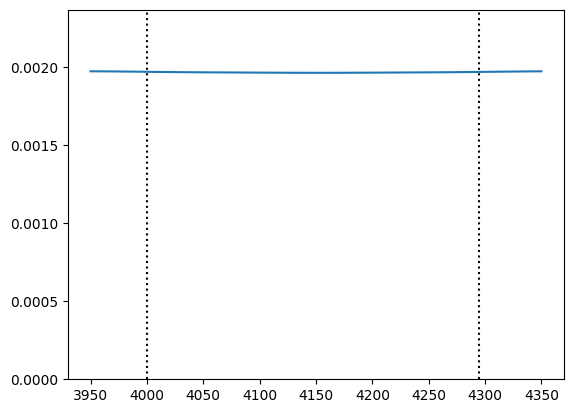

In [8]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.ylim(ymin=0)
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

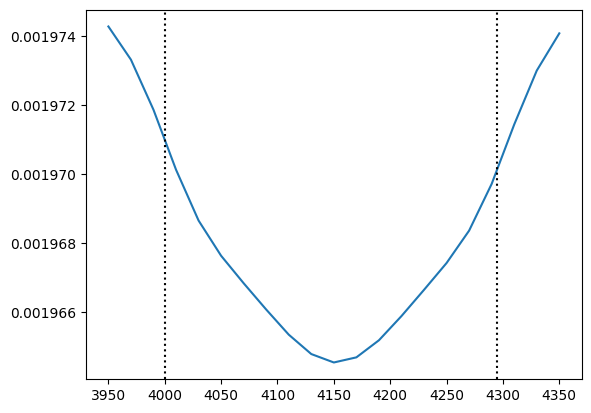

In [9]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))